# 03 - Modelo Preditivo de NPS

## Etapa 1: Alvo e amostragem

**Objetivo de negócio:** identificar quais fatores da operação derrubam a satisfação do cliente e agir antes que ele responda à pesquisa de NPS.

**Abordagem:** um modelo de classificação estima a probabilidade de cada cliente ser detrator (nota ≤ 6,5). Com ela, a operação prioriza quem abordar primeiro.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, ks_2samp
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Base

Base tratada no notebook `01-cleansing`.

In [2]:
df = pd.read_csv("../data/processed/desafio_nps_fase_1_clean.csv")
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
df.head()

Linhas: 2465 | Colunas: 19


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## Variável alvo

Categorias de NPS usadas no projeto:

| Categoria | Nota |
|---|---|
| Detrator | ≤ 6,5 |
| Neutro | acima de 6,5 até 8,5 |
| Promotor | acima de 8,5 |

A nota da base é contínua (ex.: 6,9), por isso as faixas oficiais (0–6, 7–8 e 9–10) foram convertidas em intervalos.

- `detrator`: alvo do modelo (1 = detrator, 0 = neutro ou promotor).
- `nps_categoria`: usada para estratificar a divisão entre treino e teste, garantindo neutros e promotores nos dois lados.

In [3]:
df["nps_categoria"] = pd.cut(
    df["nps_score"],
    bins=[-np.inf, 6.5, 8.5, np.inf],
    labels=["detrator", "neutro", "promotor"],
)
df["detrator"] = (df["nps_categoria"] == "detrator").astype(int)

distribuicao = pd.DataFrame({
    "quantidade": df["nps_categoria"].value_counts(),
    "proporcao_%": (df["nps_categoria"].value_counts(normalize=True) * 100).round(1),
})
distribuicao

,quantidade,proporcao_%
nps_categoria,,
detrator,1975,80.1
neutro,346,14.0
promotor,144,5.8


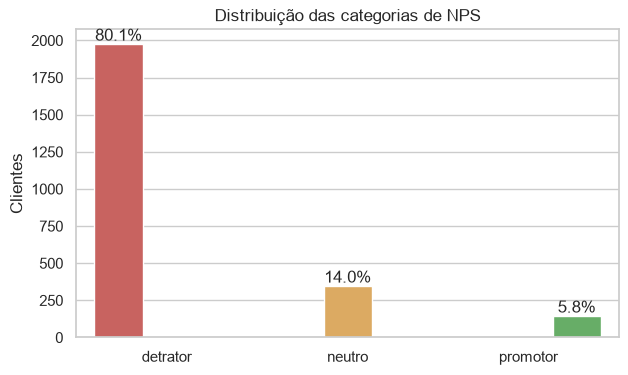

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="nps_categoria", hue="nps_categoria", ax=ax, legend=False,
              palette={"detrator": "#d9534f", "neutro": "#f0ad4e", "promotor": "#5cb85c"})
for p in ax.patches:
    ax.annotate(f"{p.get_height() / len(df):.1%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribuição das categorias de NPS")
ax.set_xlabel("")
ax.set_ylabel("Clientes")
plt.show()

**Leitura:** ~80% da base é detratora, ~14% neutra e ~6% promotora.

### Ponto de atenção: viés de seleção

É provável que clientes insatisfeitos respondam mais à pesquisa do que os satisfeitos. Se for o caso, a base retrata quem respondeu, e não a carteira inteira. Para confirmar, seria preciso cruzar com a base completa de pedidos, que não está disponível hoje.

São dois problemas diferentes:

1. **Viés de seleção (quem respondeu):** não se resolve dentro desta base, porque os satisfeitos que não responderam simplesmente não estão aqui. A solução está na coleta (pesquisar todos os pedidos ou uma amostra aleatória deles) ou em ponderar os resultados pela carteira real. Fica registrado como limitação.
2. **Desbalanceamento (como o modelo aprende):** com ~80% de detratores, o modelo tende a ignorar os satisfeitos. Esse ponto é tratado mais adiante.

## Precisamos da base inteira?

Amostra mínima pela fórmula de Cochran, com 95% de confiança, margem de ±5% e p = 0,5 (cenário mais conservador):

$$n_0 = \frac{Z^2 \cdot p(1-p)}{e^2} \qquad n = \frac{n_0}{1 + \frac{n_0 - 1}{N}}$$

In [5]:
N = len(df)
Z, p, e = 1.96, 0.5, 0.05

n0 = (Z**2 * p * (1 - p)) / e**2
n = n0 / (1 + (n0 - 1) / N)

print(f"População (N): {N}")
print(f"Amostra mínima representativa: {np.ceil(n):.0f} linhas ({np.ceil(n) / N:.1%} da base)")

População (N): 2465
Amostra mínima representativa: 333 linhas (13.5% da base)


**Decisão:** ~333 linhas bastariam para estimar proporções. Mas o objetivo aqui é treinar um modelo, e cortar dados só tira informação, principalmente dos promotores (apenas ~194). Por isso a base é usada inteira, e a amostragem fica restrita à divisão estratificada entre treino e teste.

| Técnica | Uso no projeto |
|---|---|
| Aleatória simples | ❌ pode distorcer as classes pequenas |
| **Estratificada proporcional** | ✅ divisão treino/teste, mantendo ~80/14/6 |
| Undersampling | ❌ descartaria a maior parte da base |
| Oversampling / SMOTE | ⚪ possibilidade de alternativa futura |
| **Pesos por classe** | ✅ teste de balanceamento no treino |

## Variáveis do modelo

Critério: estar disponível **antes da pesquisa** e ter mostrado relação com a nota na EDA.

| Variável | Corr. com a nota | Leitura de negócio |
|---|---|---|
| `delivery_delay_days` | -0,60 | atraso na entrega, principal alavanca operacional |
| `complaints_count` | -0,49 | reclamações registradas |
| `customer_service_contacts` | -0,35 | volume de contatos com o SAC |
| `resolution_time_days` | -0,19 | tempo para resolver o problema |

**Ficaram de fora:**
- `repeat_purchase_30d`: acontece depois da compra e praticamente entrega a resposta ao modelo (vazamento de dados);
- `csat_internal_score`: não se sabe quando é coletada, então há risco de vazamento;
- variáveis sem relação com a nota (frete, tentativas, prazo, valor do pedido, desconto, parcelas, itens, idade, tempo de relacionamento e região);
- identificadores (`customer_id`, `order_id`).

In [6]:
FEATURES = [
    "delivery_delay_days",
    "complaints_count",
    "customer_service_contacts",
    "resolution_time_days",
]
TARGET = "detrator"

X = df[FEATURES]
y = df[TARGET]

## Treino e teste

Divisão 80/20, estratificada pelas 3 categorias de NPS (e não só pelo alvo binário) para manter a proporção de neutros e promotores nas duas partes. Semente fixa (`random_state`) para reprodutibilidade.

In [7]:
X_train, X_test, y_train, y_test, cat_train, cat_test = train_test_split(
    X, y, df["nps_categoria"],
    test_size=0.2,
    stratify=df["nps_categoria"],
    random_state=RANDOM_STATE,
)

print(f"Treino: {len(X_train)} linhas | Teste: {len(X_test)} linhas")

Treino: 1972 linhas | Teste: 493 linhas


## Treino e teste representam a base?

- **Categorias:** teste qui-quadrado.
- **Variáveis:** teste de Kolmogorov-Smirnov.

p-valor acima de 0,05 nos dois testes indica que treino e teste são representativos.

In [8]:
comparacao = pd.DataFrame({
    "base_completa_%": df["nps_categoria"].value_counts(normalize=True) * 100,
    "treino_%": cat_train.value_counts(normalize=True) * 100,
    "teste_%": cat_test.value_counts(normalize=True) * 100,
}).round(1)
comparacao

,base_completa_%,treino_%,teste_%
nps_categoria,,,
detrator,80.1,80.1,80.1
neutro,14.0,14.0,14.0
promotor,5.8,5.8,5.9


In [9]:
tabela = pd.DataFrame({
    "treino": cat_train.value_counts(),
    "teste": cat_test.value_counts(),
})
chi2, p_valor, _, _ = chi2_contingency(tabela)
print(f"Qui-quadrado: {chi2:.3f} | p-valor: {p_valor:.3f}")

Qui-quadrado: 0.002 | p-valor: 0.999


In [10]:
ks = pd.DataFrame(
    [(col, *ks_2samp(X_train[col], X_test[col])) for col in FEATURES],
    columns=["variavel", "estatistica_ks", "p_valor"],
).round(3)
ks["representativa"] = np.where(ks["p_valor"] > 0.05, "sim", "não")
ks

,variavel,estatistica_ks,p_valor,representativa
0,delivery_delay_days,0.034,0.745,sim
1,complaints_count,0.025,0.965,sim
2,customer_service_contacts,0.052,0.227,sim
3,resolution_time_days,0.035,0.695,sim


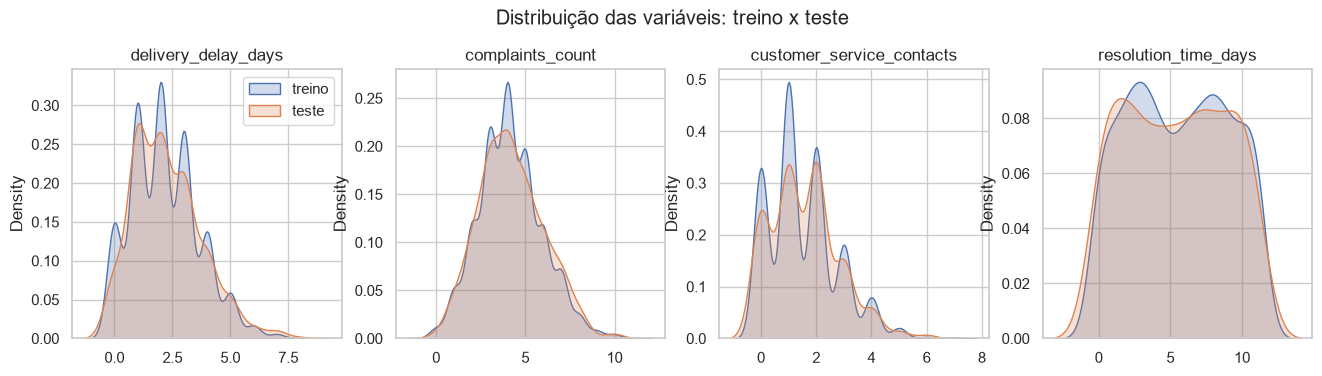

In [11]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(16, 3.5))
for ax, col in zip(axes, FEATURES):
    sns.kdeplot(X_train[col], ax=ax, label="treino", fill=True)
    sns.kdeplot(X_test[col], ax=ax, label="teste", fill=True)
    ax.set_title(col)
    ax.set_xlabel("")
axes[0].legend()
plt.suptitle("Distribuição das variáveis: treino x teste", y=1.05)
plt.show()

## Desbalanceamento

Aplicamos pesos por classe (`class_weight="balanced"`) para que errar um cliente satisfeito custe mais no treino:

$$w_c = \frac{n_{amostras}}{n_{classes} \cdot n_c}$$

- Os pesos valem só no treino. O teste mantém a proporção real (~80% de detratores), que é o cenário que a operação vai encontrar.
- Acurácia não serve como métrica principal: um modelo que chama todo mundo de detrator já acerta ~80%.

In [12]:
classes = np.unique(y_train)
pesos = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
pd.DataFrame({
    "classe": ["não detrator (0)", "detrator (1)"],
    "qtd_treino": [(y_train == c).sum() for c in classes],
    "peso": pesos.round(3),
})

,classe,qtd_treino,peso
0,não detrator (0),392,2.515
1,detrator (1),1580,0.624


## Validação cruzada

Validação cruzada estratificada com 5 folds no treino para escolher o modelo. O teste fica guardado para a avaliação final.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for i, (_, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Fold {i}: {len(idx_val)} linhas | detratores: {y_train.iloc[idx_val].mean():.1%}")

Fold 1: 395 linhas | detratores: 80.0%
Fold 2: 395 linhas | detratores: 80.0%
Fold 3: 394 linhas | detratores: 80.2%
Fold 4: 394 linhas | detratores: 80.2%
Fold 5: 394 linhas | detratores: 80.2%


## Resumo da etapa 1

- **Alvo:** detrator (nota ≤ 6,5), com estratificação pelas 3 categorias de NPS.
- **Base:** completa (2.465 linhas).
- **Divisão:** 80/20 estratificada, com representatividade confirmada (qui-quadrado e Kolmogorov-Smirnov).
- **Desbalanceamento:** pesos por classe no treino; teste com a proporção real.
- **Limitação:** possível viés de seleção nas respostas da pesquisa.

# Etapa 2: Modelagem, versão A (com pesos)

Três modelos comparados:

| Modelo | Papel |
|---|---|
| `DummyClassifier` | **linha de base:** chuta pela proporção da base, sem olhar as variáveis. Todo modelo útil precisa superá-lo. |
| `LogisticRegression` | **modelo principal:** simples e explicável, mostra o peso de cada fator operacional. |
| `RandomForestClassifier` | **comparação:** capta relações não lineares e interações entre variáveis. |

Todos com `class_weight="balanced"`.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    make_scorer, recall_score, precision_score, roc_auc_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
)

CLASS_WEIGHT = "balanced"  # versão A (com pesos)
VERSAO = "com_pesos"

## Configuração dos modelos

- **Regressão logística:** variáveis padronizadas com `StandardScaler` dentro do pipeline, ajustado só no treino de cada fold. Isso evita vazamento e deixa os coeficientes comparáveis.
- **Random forest:** profundidade máxima 5 e mínimo de 20 clientes por folha, para não decorar uma base pequena.

In [14]:
modelos = {
    "Dummy (linha de base)": DummyClassifier(strategy="prior"),
    "Regressão logística": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight=CLASS_WEIGHT, max_iter=1000, random_state=RANDOM_STATE),
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=20,
        class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

## Resultado na validação cruzada

| Métrica | Pergunta de negócio |
|---|---|
| **ROC-AUC** | O modelo ordena bem os clientes por risco? (0,5 = sorteio, 1 = perfeito) |
| **Recall detrator** | De todos os detratores, quantos o modelo pega? |
| **Precisão detrator** | Dos alertas, quantos eram mesmo detratores? |
| **Recall não detrator** | Dos satisfeitos, quantos o modelo reconhece? Esse número não pode zerar. |
| **F1 macro** | Equilíbrio entre as duas classes |

In [15]:
SCORING = {
    "roc_auc": "roc_auc",
    "recall_detrator": make_scorer(recall_score, pos_label=1),
    "precisao_detrator": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall_nao_detrator": make_scorer(recall_score, pos_label=0),
    "f1_macro": "f1_macro",
}

resultados_cv = {}
for nome, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv, scoring=SCORING)
    resultados_cv[nome] = {
        metrica: f"{scores[f'test_{metrica}'].mean():.3f} ± {scores[f'test_{metrica}'].std():.3f}"
        for metrica in SCORING
    }

pd.DataFrame(resultados_cv).T

,roc_auc,recall_detrator,precisao_detrator,recall_nao_detrator,f1_macro
Dummy (linha de base),0.500 ± 0.000,1.000 ± 0.000,0.801 ± 0.001,0.000 ± 0.000,0.445 ± 0.000
Regressão logística,0.891 ± 0.005,0.791 ± 0.019,0.943 ± 0.007,0.809 ± 0.027,0.735 ± 0.012
Random forest,0.882 ± 0.010,0.799 ± 0.027,0.936 ± 0.006,0.778 ± 0.029,0.732 ± 0.012


## Quatro variáveis bastam?

As variáveis descartadas tinham correlação quase nula com a nota, mas para confirmar, comparamos o AUC com as 4 variáveis e com todas as disponíveis antes da pesquisa (exceto `repeat_purchase_30d` e `csat_internal_score`, pelo risco de vazamento).

In [16]:
CANDIDATAS = FEATURES + [
    "freight_value", "delivery_attempts", "delivery_time_days", "order_value",
    "discount_value", "payment_installments", "items_quantity",
    "customer_age", "customer_tenure_months",
]
X_todas = pd.get_dummies(df[CANDIDATAS + ["customer_region"]], columns=["customer_region"], drop_first=True, dtype=int)
X_todas_train = X_todas.loc[X_train.index]

parcimonia = {}
for nome in ["Regressão logística", "Random forest"]:
    for rotulo, X_cv in [("4 variáveis", X_train), ("todas as candidatas", X_todas_train)]:
        auc = cross_validate(modelos[nome], X_cv, y_train, cv=cv, scoring="roc_auc")["test_score"]
        parcimonia[(nome, rotulo)] = {"roc_auc_medio": auc.mean().round(3), "desvio": auc.std().round(3)}

pd.DataFrame(parcimonia).T

roc_auc_medio  desvio
Regressão logística 4 variáveis                  0.891   0.005
                    todas as candidatas          0.888   0.005
Random forest       4 variáveis                  0.882   0.010
                    todas as candidatas          0.875   0.013

Dessa maneira, consideramos o modelo enxuto.

## Avaliação final no teste

Modelos treinados com todo o treino e avaliados uma única vez no teste, que mantém a proporção real. Corte padrão: probabilidade ≥ 0,5 = detrator.

In [17]:
probas, predicoes, metricas_teste = {}, {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    probas[nome] = modelo.predict_proba(X_test)[:, 1]
    predicoes[nome] = (probas[nome] >= 0.5).astype(int)
    metricas_teste[nome] = {
        "roc_auc": roc_auc_score(y_test, probas[nome]),
        "recall_detrator": recall_score(y_test, predicoes[nome], pos_label=1),
        "precisao_detrator": precision_score(y_test, predicoes[nome], pos_label=1, zero_division=0),
        "recall_nao_detrator": recall_score(y_test, predicoes[nome], pos_label=0),
        "precisao_nao_detrator": precision_score(y_test, predicoes[nome], pos_label=0, zero_division=0),
        "f1_macro": f1_score(y_test, predicoes[nome], average="macro"),
    }

pd.DataFrame(metricas_teste).T.round(3)

,roc_auc,recall_detrator,precisao_detrator,recall_nao_detrator,precisao_nao_detrator,f1_macro
Dummy (linha de base),0.500,1.000,0.801,0.000,0.000,0.445
Regressão logística,0.877,0.813,0.941,0.796,0.513,0.748
Random forest,0.880,0.813,0.933,0.765,0.503,0.738


In [18]:
print(classification_report(
    y_test, predicoes["Regressão logística"],
    target_names=["não detrator (0)", "detrator (1)"], digits=3,
))

                  precision    recall  f1-score   support

não detrator (0)      0.513     0.796     0.624        98
    detrator (1)      0.941     0.813     0.872       395

        accuracy                          0.809       493
       macro avg      0.727     0.804     0.748       493
    weighted avg      0.856     0.809     0.823       493



### Matrizes de confusão

Os dois erros que importam: **falso negativo** (detrator que passou batido) e **falso positivo** (cliente satisfeito abordado sem necessidade).

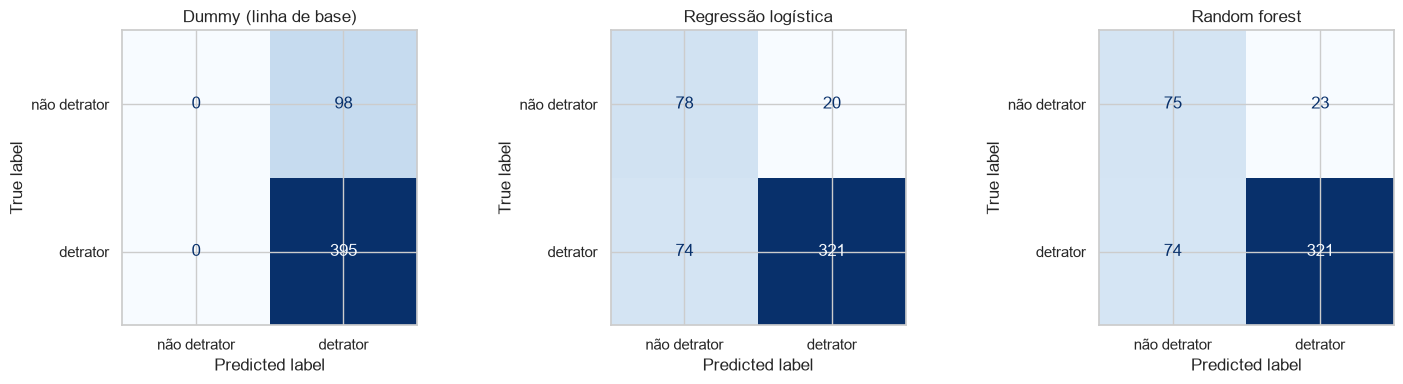

In [20]:
fig, axes = plt.subplots(1, len(modelos), figsize=(15, 4))
for ax, nome in zip(axes, modelos):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, predicoes[nome]),
        display_labels=["não detrator", "detrator"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

### Curva ROC

Quanto mais longe da diagonal, melhor o modelo separa clientes de alto e de baixo risco.

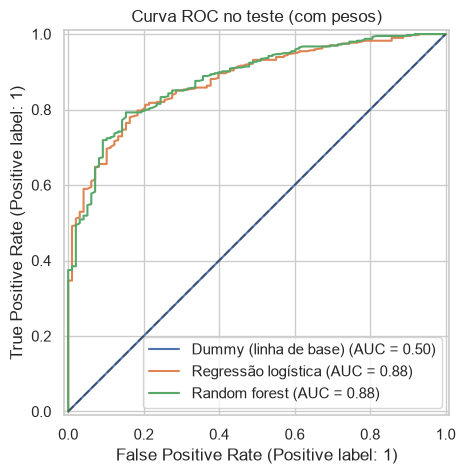

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
for nome in modelos:
    RocCurveDisplay.from_predictions(y_test, probas[nome], name=nome, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title(f"Curva ROC no teste ({VERSAO.replace('_', ' ')})")
plt.show()

## Quais fatores pesam na satisfação?

- **Regressão logística:** coeficiente positivo aumenta o risco de detrator. A razão de chances (*odds ratio*) mostra quanto esse risco se multiplica a cada desvio padrão a mais na variável.
- **Random forest:** mostra a importância de cada variável, mas não a direção do efeito.

In [22]:
logreg = modelos["Regressão logística"].named_steps["logisticregression"]
interpretacao = pd.DataFrame({
    "coeficiente": logreg.coef_[0],
    "razao_de_chances": np.exp(logreg.coef_[0]),
    "importancia_rf": modelos["Random forest"].feature_importances_,
}, index=FEATURES).sort_values("coeficiente", ascending=False).round(3)
interpretacao

,coeficiente,razao_de_chances,importancia_rf
delivery_delay_days,1.627,5.087,0.487
complaints_count,1.144,3.138,0.361
resolution_time_days,0.653,1.921,0.083
customer_service_contacts,0.130,1.139,0.068


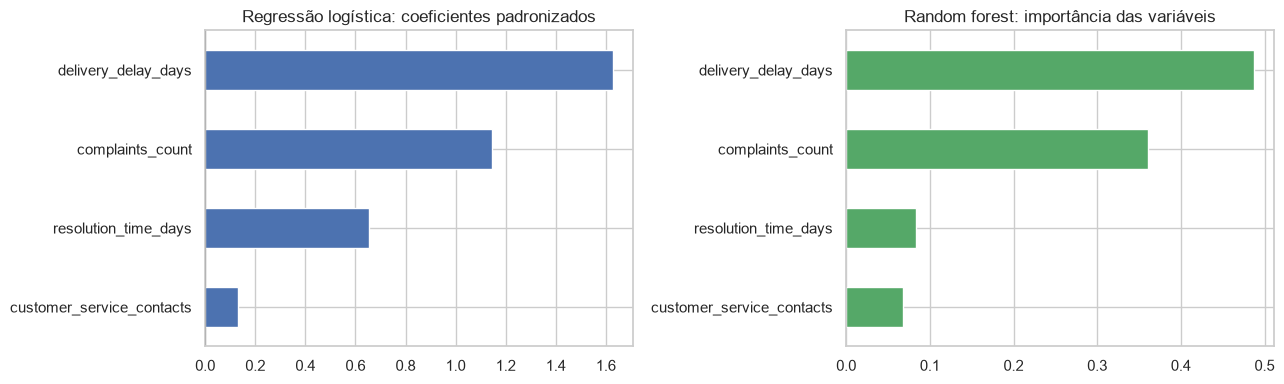

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
interpretacao["coeficiente"].sort_values().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Regressão logística: coeficientes padronizados")
interpretacao["importancia_rf"].sort_values().plot.barh(ax=axes[1], color="#55a868")
axes[1].set_title("Random forest: importância das variáveis")
plt.tight_layout()
plt.show()

## Ponto de corte

O corte de 0,5 é só o ponto de partida. O valor final deve ser definido com a operação, de acordo com quantos clientes a equipe consegue abordar: corte alto gera menos alertas e mais certeiros; corte baixo gera mais alertas e cobre mais detratores.

A tabela mostra o efeito de cada corte na regressão logística.

In [25]:
proba_lr = probas["Regressão logística"]
cortes = []
for corte in np.arange(0.3, 0.91, 0.1):
    pred = (proba_lr >= corte).astype(int)
    cortes.append({
        "corte": round(corte, 1),
        "clientes_alertados_%": round(pred.mean() * 100, 1),
        "recall_detrator": recall_score(y_test, pred, pos_label=1),
        "precisao_detrator": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "recall_nao_detrator": recall_score(y_test, pred, pos_label=0),
    })
pd.DataFrame(cortes).round(3)

,corte,clientes_alertados_%,recall_detrator,precisao_detrator,recall_nao_detrator
0,0.3,79.7,0.896,0.901,0.602
1,0.4,74.6,0.853,0.916,0.684
2,0.5,69.2,0.813,0.941,0.796
3,0.6,62.3,0.742,0.954,0.857
4,0.7,54.4,0.656,0.966,0.908
5,0.8,43.8,0.537,0.981,0.959
6,0.9,29.4,0.365,0.993,0.990


### Priorização por ranking de risco

Alternativa ao corte: ordenar os clientes por risco e atuar nos X% do topo. O *lift* compara a taxa de detratores de cada faixa com a média do teste. Quanto maior, mais vale priorizar pelo modelo em vez de escolher ao acaso.

In [26]:
ranking = pd.DataFrame({"proba": proba_lr, "detrator": y_test.values}).sort_values("proba", ascending=False)
taxa_geral = ranking["detrator"].mean()
faixas = []
for top in [0.1, 0.2, 0.3, 0.5]:
    grupo = ranking.head(int(len(ranking) * top))
    faixas.append({
        "top_%_de_risco": int(top * 100),
        "clientes": len(grupo),
        "taxa_detratores_%": round(grupo["detrator"].mean() * 100, 1),
        "lift": round(grupo["detrator"].mean() / taxa_geral, 2),
    })
print(f"Taxa geral de detratores no teste: {taxa_geral:.1%}")
pd.DataFrame(faixas)

Taxa geral de detratores no teste: 80.1%


,top_%_de_risco,clientes,taxa_detratores_%,lift
0,10,49,100.0,1.25
1,20,98,100.0,1.25
2,30,147,99.3,1.24
3,50,246,97.6,1.22


## Exportação das predições

Probabilidades do teste salvas em `reports/`. Como as versões A e B usam a mesma divisão, dá para comparar as duas cliente a cliente (teste de McNemar ou bootstrap da diferença de AUC).

In [26]:
predicoes_teste = pd.DataFrame({"indice": X_test.index, "detrator_real": y_test.values})
for nome in modelos:
    chave = nome.split(" (")[0].lower().replace(" ", "_").replace("ã", "a")
    predicoes_teste[f"proba_{chave}"] = probas[nome]

caminho = f"../reports/predicoes_teste_{VERSAO}.csv"
predicoes_teste.to_csv(caminho, index=False)
print(f"Predições salvas em {caminho} ({len(predicoes_teste)} linhas)")

Predições salvas em ../reports/predicoes_teste_com_pesos.csv (493 linhas)


## Conclusão da versão A (com pesos)

**Desempenho**
- AUC de ~0,88 no teste, contra 0,50 da linha de base. Validação cruzada (~0,89) e teste batem, sem sinal de sobreajuste.
- Regressão logística e random forest empatam. Fica a **regressão logística**, mais simples e mais fácil de explicar.
- No corte de 0,5, ela pega **~81% dos detratores** com **~94% de precisão** e reconhece **~80% dos satisfeitos**. A linha de base reconhece 0%.
- Mais variáveis não ajudam (AUC de 0,888 contra 0,891). As 4 selecionadas bastam.

**O que derruba a satisfação**
1. **Atraso na entrega:** principal fator. Cada desvio padrão a mais de atraso multiplica por ~5 a chance de o cliente ser detrator.
2. **Reclamações:** multiplicam a chance por ~3.
3. **Tempo de resolução:** multiplica por ~1,9.
4. **Contatos com o SAC:** efeito pequeno quando os outros fatores já estão no modelo. A informação provavelmente já vem das reclamações.

**Como usar**
- Ajustar o corte à capacidade da equipe. Com corte de 0,7, o modelo sinaliza ~54% dos clientes com ~97% de precisão.
- Atuar pelo ranking: os 20% de maior risco são **100% detratores**. O *lift* (~1,25) é baixo só porque a base já tem ~80% de detratores.
- Possibilidade de ações: monitorar atrasos e reclamações em tempo real, fazer contato proativo ou oferecer compensação aos clientes de maior risco antes da pesquisa e reduzir o tempo de resolução no SAC.